In [1]:
!pip install OMIEData

  Using cached OMIEData-0.3.0.0-py3-none-any.whl.metadata (5.9 kB)
  Using cached DateTime-5.5-py3-none-any.whl.metadata (33 kB)
Using cached OMIEData-0.3.0.0-py3-none-any.whl (24 kB)
Using cached DateTime-5.5-py3-none-any.whl (52 kB)


In [11]:
import datetime as dt
import OMIEData
from OMIEData.DataImport.omie_supply_demand_curve_importer import OMIESupplyDemandCurvesImporter

# Press the green button in the gutter to run the script.
if __name__ == '__main__':

    dateIni = dt.datetime(2023, 1, 1)
    dateEnd = dt.datetime(2023, 1, 1)
    hour = 1

    # This can take time, it is downloading the files from the website..
    df = OMIESupplyDemandCurvesImporter(date_ini=dateIni, date_end=dateEnd, hour=hour).read_to_dataframe(verbose=True)
    df.sort_values(by=['DATE', 'HOUR'], axis=0, inplace=True)
    print(df)

Requesting https://www.omie.es/sites/default/files/dados/AGNO_2023/MES_01/TXT/INT_CURVA_ACUM_UO_MIB_1_1_01_01_2023_01_01_2023.TXT ...
Url: https://www.omie.es/sites/default/files/dados/AGNO_2023/MES_01/TXT/INT_CURVA_ACUM_UO_MIB_1_1_01_01_2023_01_01_2023.TXT successfully processed
            DATE HOUR COUNTRY UNIT OFFER_TYPE  ENERGY   PRICE MATCHED
0     01/01/2023    1      MI  NaN          C   460.6  1500.0       O
1     01/01/2023    1      MI  NaN          C    29.8  1002.0       O
2     01/01/2023    1      MI  NaN          C    24.3  1002.0       O
3     01/01/2023    1      MI  NaN          C     5.8  1002.0       O
4     01/01/2023    1      MI  NaN          C     1.4  1002.0       O
...          ...  ...     ...  ...        ...     ...     ...     ...
2612  01/01/2023    1      MI  NaN          V    23.0     0.0       C
2613  01/01/2023    1      MI  NaN          V     9.1     0.0       C
2614  01/01/2023    1      MI  NaN          V     1.9     0.0       C
2615  01/01/2023   

c:\Users\DBT3KD\AppData\Local\miniconda3\Lib\site-packages\OMIEData\DataImport\omie_data_importer_from_responses.py:29: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, self.fileReader.get_data_from_response(response=response)], ignore_index=True)


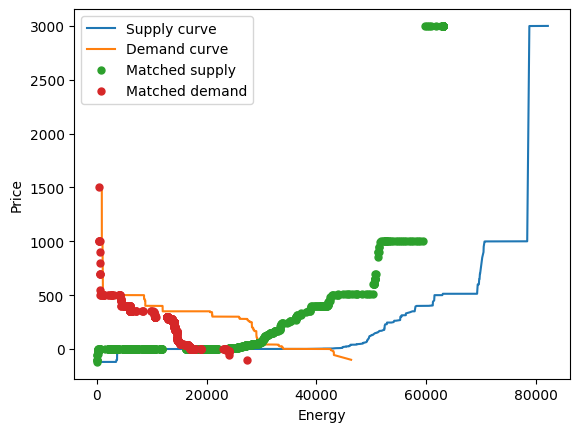

In [12]:
import matplotlib.pyplot as plt

# Filtrer les courbes d'offre et de demande
supply_curve = df[df['OFFER_TYPE'] == 'V'].sort_values(by='PRICE', ascending=True)
supply_curve['cum_energy'] = supply_curve['ENERGY'].cumsum()
demand_curve = df[df['OFFER_TYPE'] == 'C'].sort_values(by='PRICE', ascending=False)
demand_curve['cum_energy'] = demand_curve['ENERGY'].cumsum()

# Filtrer les offres et demandes qui ont été "matched"
matched_supply_curve = df[(df['OFFER_TYPE'] == 'V') & (df['MATCHED'] == 'O')].sort_values(by='PRICE', ascending=True)
matched_supply_curve['cum_energy'] = matched_supply_curve['ENERGY'].cumsum()
matched_demand_curve = df[(df['OFFER_TYPE'] == 'C') & (df['MATCHED'] == 'O')].sort_values(by='PRICE', ascending=False)
matched_demand_curve['cum_energy'] = matched_demand_curve['ENERGY'].cumsum()

# Tracer les courbes
plt.plot(supply_curve['cum_energy'], supply_curve['PRICE'], label='Supply curve')
plt.plot(demand_curve['cum_energy'], demand_curve['PRICE'], label='Demand curve')
plt.plot(matched_supply_curve['cum_energy'], matched_supply_curve['PRICE'], 'o', label='Matched supply', markersize=5)
plt.plot(matched_demand_curve['cum_energy'], matched_demand_curve['PRICE'], 'o', label='Matched demand', markersize=5)

plt.xlabel('Energy')
plt.ylabel('Price')
plt.legend()
plt.show()



In [14]:
df.iloc[1,]

DATE          01/01/2023
HOUR                   1
COUNTRY               MI
UNIT                 NaN
OFFER_TYPE             C
ENERGY              29.8
PRICE             1002.0
MATCHED                O
Name: 1, dtype: object